In [13]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from pre_processing import pre_process, json_decode


sns.set_palette("hsv_r")

# This affects things like the size of the labels, lines, and other elements of the plot, but not the overall style. 
# The base context is “notebook”, and the other contexts are “paper”, “talk”, and “poster”, which are version of 
# the notebook parameters scaled by .8, 1.3, and 1.6, respectively.
sns.set_context("talk")

%config Inline.figure_format = 'retina'
%matplotlib inline

## Read in Data 

In [14]:
# File paths for each experimental condition (can contain multiple subjects/files) 
file_paths_baseline = [
    "../data/csv_files/07_baseline.csv", 
]

file_paths_repulse = [
    "../data/csv_files/abby_test_repulse.csv", 
]

file_paths_udl = [
    "../data/csv_files/07_udl.csv", 
]

# Subject identifiers corresponding to the datasets
# Actual participants have randomly generated KinArm IDs
subject_list = ["abby"]    

# Load CSV files & label condition
df_baseline_raw = pre_process(file_paths_baseline, subject_list)
df_baseline_raw['phase'] = 'baseline'

df_repulse_raw = pre_process(file_paths_repulse, subject_list)
df_repulse_raw['phase'] = 'repulse'

df_udl_raw = pre_process(file_paths_udl, subject_list)
df_udl_raw['phase'] = 'udl'

# Combine all conditions into a single dataset
df = pd.concat([df_baseline_raw, df_repulse_raw, df_udl_raw]).reset_index(drop=True)

# Reset the trial number column that resets for each subject
df["TN"] = df.groupby("SN").cumcount() + 1
df

,SN,TN,target_angle,probe,feedback,reach_feedback,rt,mt,peak_vel,theta_40,theta_100,theta_pv,theta_end,Subject ID,phase
0,1,1,330,0,0,good reach,1.053,0.299,43.800950,-9.772827,-8.987842,-1.397609,-1.397609,abby,baseline
1,1,2,90,0,0,too early,0.554,0.255,6.260504,8.453117,4.850505,28.517069,28.517069,abby,baseline
2,1,3,0,0,0,good reach,0.971,0.211,67.095610,-1.553245,-0.469152,0.825023,0.825023,abby,baseline
3,1,4,120,0,0,good reach,0.920,0.226,45.951262,8.890186,5.994496,4.139114,2.764028,abby,baseline
4,1,5,30,0,0,too early,0.422,NaN,10.144196,11.157359,11.550198,6.670767,6.670767,abby,baseline
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1715,1,1716,60,0,0,good reach,0.652,0.248,44.562413,2.086366,3.267749,3.456925,2.771480,abby,udl
1716,1,1717,60,0,0,too early,0.414,0.264,8.484159,-3.177115,-0.565437,-33.137016,-33.137016,abby,udl
1717,1,1718,60,0,0,good reach,0.753,0.269,43.703028,-1.756312,-1.323743,-0.983824,-0.674509,abby,udl
1718,1,1719,60,0,0,good reach,0.726,0.227,47.261750,-0.233471,-0.015832,0.025214,-0.954666,abby,udl


## Define Functions 

In [ ]:
# function to unpack repeated target value from series
# WE HAVENT USE THIS ONE YET.. copied from Jeremy's analysis script
def find_rep(group):
    vals = group['Repeated_Target'].iloc[0]
    return vals[1:4]   


def N_finder(group, N_minus_targ):
    
    # Find trials where N-1 had the specified target
    N_trial_num = (group.loc[group['target_angle'] == N_minus_targ,'TN'] + 1)

    # Return trial N
    N_df = group.loc[group['TN'].isin(N_trial_num)]
    return N_df


def calculate_se_index(df, y_col):
    """
    calculate the sequential effect (SE) index per participant 
    POSITIVE SE Index = attractive bias (UDL)
    NEGATIVE SE Index = repulsive bias (REPULSE)

    parameters: 
    df : DataFrame; data to calculate SE index from
    y_col : str; column containing corrected bias

    output: 
    df with the SE index per participant 
    """
    negative_mean = df.loc[df["target_angle_diff"] < 0].groupby("SN")[y_col].mean()
    positive_mean = df.loc[df["target_angle_diff"] > 0].groupby("SN")[y_col].mean()

    return negative_mean - positive_mean 

def circ_dist(ang1, ang2):

    ang1rad = np.deg2rad(ang1)
    ang2rad = np.deg2rad(ang2)
    ang_dist = np.rad2deg(np.arctan2(np.sin(ang1rad), np.cos(ang2rad)))

    return ang_dist


def add_bias_correction(df, angle_col, phase_name, epoch):
    """
    calculate target-specific bias and corrected angle for a given phase and angle column
    """
    bias_col = f"bias_{phase_name}_{angle_col}"
    corrected_col = f"corrected_{phase_name}_{angle_col}"

    bias = (
        df.loc[
            (df["TN"] >= epoch[0]) &
            (df["TN"] <= epoch[1]) &
            (df["rt"] > 0.5) &
            (df[angle_col].abs() < 60)
        ]
        .groupby(["SN", "target_angle"], as_index=False)[angle_col]
        .mean()
        .rename(columns={angle_col: bias_col})
    )

    # merge bias back into dataframe
    df = df.merge(bias, on=["SN", "target_angle"], how="left")

    # wrap the angle
    diff = np.deg2rad(df[angle_col] - df[bias_col])

    df[corrected_col] = np.rad2deg(
        np.arctan2(np.sin(diff), np.cos(diff))
    )
    return df


## should probably create a function that determines the repeated target and changes all the targets to be centred around ZERO 

## Data Wrangling 

In [16]:
## Define epochs for each phase of the experiment (trial number ranges for each phase)
epochs = {
    'baseline': (1, 17),                # Baseline reaching
    'repulse':(17, 717),                # Main experiment block
    'repulse_clean':(117, 717),         # For repulse bias correctinon
    'udl_baseline_FB': (717, 787),      # Baseline reaching 
    'udl_baseline_noFB': (787, 857),    # For UDL bias corrrection  
    'udl':(857, 1721),                  # Main experiment block
    'udl_full':(717, 1721),             # including the baseline
}

# Central/repeated target angle for each participant
# Update this dictionary as new participants are added
central_target = {
    1: 60,
}

# Shift target angles so each participant's central target = 0°
for sn, central_angle in central_target.items():
    mask = df["SN"] == sn
    TA_rad_shift = df.loc[mask, "target_angle"] - central_angle
    df.loc[mask, "target_angle"] = circ_dist(TA_rad_shift, TA_rad_shift).round()

# Get target angle difference (delta target angle) values
df['target_angle_diff'] = pd.Series(pd.NA, index=df.index, dtype='Float64')
# NOTES:
# 1) CW is negative, CCW is positive 

mask = (df['TN'] >= epochs['repulse'][0]) & (df['TN'] < epochs['repulse'][1])
RadTAN1diff_repulse = np.deg2rad(df.loc[mask].groupby('SN')['target_angle'].diff(periods=1))
df.loc[mask,'target_angle_diff'] = np.rad2deg(np.arctan2(np.sin(RadTAN1diff_repulse), np.cos(RadTAN1diff_repulse)))

mask = (df['TN'] >= epochs['udl_full'][0]) & (df['TN'] < epochs['udl_full'][1])
RadTAN1diff_udl = np.deg2rad(df.loc[mask].groupby('SN')['target_angle'].diff(periods=1))
df.loc[mask,'target_angle_diff'] = np.rad2deg(np.arctan2(np.sin(RadTAN1diff_udl), np.cos(RadTAN1diff_udl)))

# Round 
df['target_angle_diff'] = df['target_angle_diff'].round().astype('Int64')


########################### CHANGED HERE #####################################################################

# Calculate bias for each participant (for REPULSE), which is used for bias correction in the UDL condition
bias_subset = (
    df.loc[(df['TN'] >= epochs['repulse_clean'][0]) & (df['TN'] < epochs['repulse_clean'][1]) & 
  #  (df['reach_feedback'] == 'good reach') & 
    (df['theta_pv'].abs() < 60)]
    .groupby(['SN', 'target_angle'], as_index=False)['theta_pv']
    .mean()
    .rename(columns={'theta_pv': 'bias_repulse'})
)
df = df.merge(bias_subset, on=['SN', 'target_angle'], how='left')
# Correct for target-level reach biases (for REPULSE) by subtraction of mean hand angle to a target
RadCorrDiff = np.deg2rad(df['theta_pv'] - df['bias_repulse'])

df['corrected_bias_repulse'] = np.rad2deg(np.arctan2(np.sin(RadCorrDiff), np.cos(RadCorrDiff)))

# Calculate bias for each participant (for UDL), which is used for bias correction in the UDL condition
bias_subset = (
    df.loc[(df['TN'] >= epochs['udl_baseline_noFB'][0]) & (df['TN'] < epochs['udl_baseline_noFB'][1]) & 
    # (df['reach_feedback'] == 'good reach') & 
    (df['theta_pv'].abs() < 60)]
    .groupby(['SN', 'target_angle'], as_index=False)['theta_pv']
    .mean()
    .rename(columns={'theta_pv': 'bias_udl'})
)
df = df.merge(bias_subset, on=['SN', 'target_angle'], how='left')
# Correct for target-level reach biases (for UDL) by subtraction of mean hand angle to a target
RadCorrDiff = np.deg2rad(df['theta_pv'] - df['bias_udl'])
df['corrected_bias_udl'] = np.rad2deg(np.arctan2(np.sin(RadCorrDiff), np.cos(RadCorrDiff)))

# REPULSE: very lax filtering 

Text(0, 0.5, 'Corrected Bias')

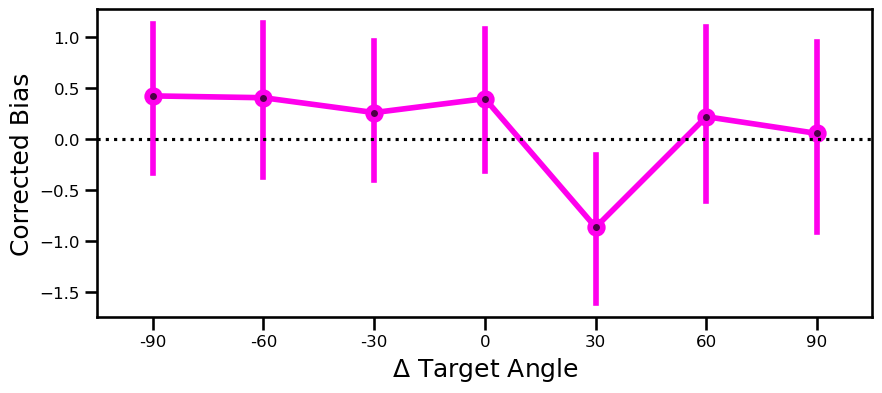

In [17]:
repulse_mask = (
    (df['TN'] >= epochs['repulse_clean'][0]) & (df['TN'] < epochs['repulse_clean'][1]) & 
    (df["target_angle_diff"].abs() <= 90) &
    (np.abs(df['theta_pv']) < 60)
)

df_repulse_lax = df.loc[repulse_mask].copy()

subject_means_repulse = (
    df_repulse_lax
    .groupby(['SN', 'target_angle_diff'])['corrected_bias_repulse']
    .mean()
    .reset_index()
)

fig2, ax2 = plt.subplots(figsize=(10,4))
sns.pointplot(
    data=df_repulse_lax,
    x='target_angle_diff',
    y='corrected_bias_repulse',
    # y='bias_repulse',
    estimator='mean',
    errorbar=('ci',95),
    #color='black',
    ax=ax2
)
sns.stripplot(
    data=subject_means_repulse,
    x='target_angle_diff',
    y='corrected_bias_repulse',
    # y='bias_repulse',
    color='black',
    alpha=0.7,
    jitter=0.15,
    size=5,
    ax=ax2
)
ax2.axhline(0, color='black', linestyle=':')
ax2.tick_params(axis='x', labelsize=12)
ax2.tick_params(axis='y', labelsize=12)
plt.xlabel(r'$\Delta$ Target Angle')
plt.ylabel('Corrected Bias')


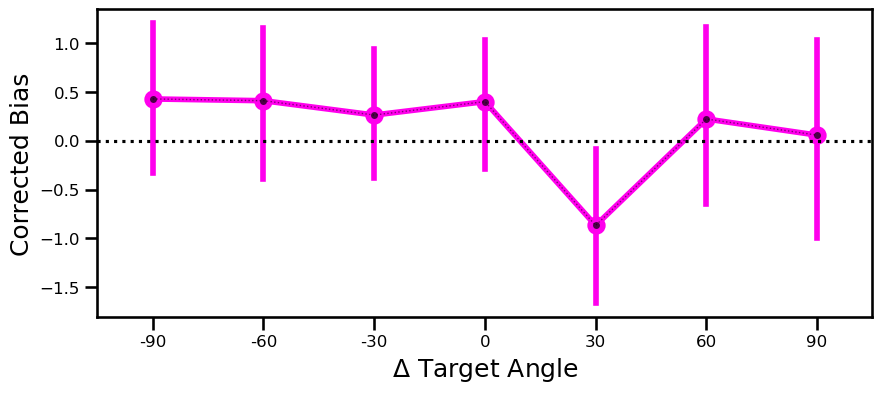

In [18]:
fig2, ax2 = plt.subplots(figsize=(10,4))

# Group mean + 95% CI
sns.pointplot(
    data=df_repulse_lax,
    x='target_angle_diff',
    y='corrected_bias_repulse',
    estimator='mean',
    errorbar=('ci', 95),
    ax=ax2
)

# Get x-category order for positioning the participant lines
x_order = sorted(df_repulse_lax['target_angle_diff'].unique())

# Connect each participant's dots
for sn, sub in subject_means_repulse.groupby('SN'):
    sub = sub.sort_values('target_angle_diff')

    x_positions = [
        x_order.index(x)
        for x in sub['target_angle_diff']
    ]

    ax2.plot(
        x_positions,
        sub['corrected_bias_repulse'],
        color='black',
        linewidth=1,
        linestyle=':',
        alpha=0.5
    )

# Individual participant means
sns.stripplot(
    data=subject_means_repulse,
    x='target_angle_diff',
    y='corrected_bias_repulse',
    color='black',
    alpha=0.7,
    jitter=0,
    size=5,
    ax=ax2
)

ax2.axhline(0, color='black', linestyle=':')
ax2.tick_params(axis='x', labelsize=12)
ax2.tick_params(axis='y', labelsize=12)

plt.xlabel(r'$\Delta$ Target Angle')
plt.ylabel('Corrected Bias')

plt.show()

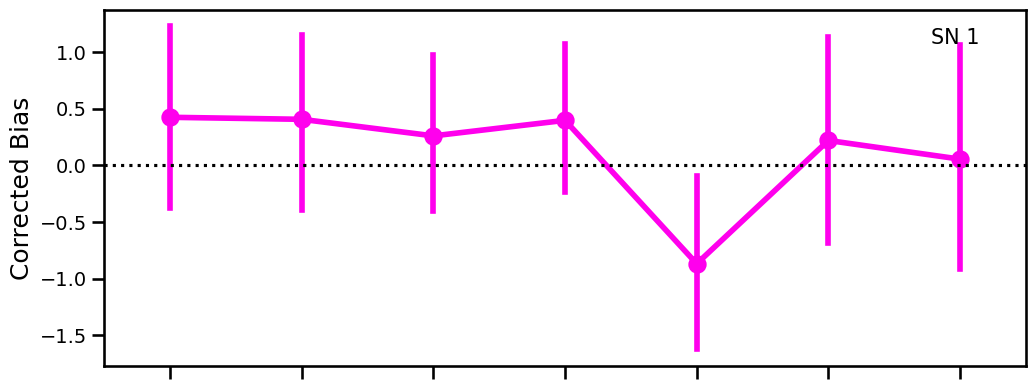

In [19]:
participants = sorted(df_repulse_lax['SN'].unique())

fig, axes = plt.subplots(3, 2, figsize=(20, 12), sharex=True, sharey=True)
axes = axes.flatten()

for ax, subject_num in zip(axes, participants):

    sns.pointplot(
        data=df_repulse_lax[df_repulse_lax['SN'] == subject_num],
        x='target_angle_diff',
        y='corrected_bias_repulse',
        estimator='mean',
        errorbar=('ci', 95),
        ax=ax
    )

    ax.axhline(0, color='black', linestyle=':')
    ax.tick_params(axis='x', labelsize=14)
    ax.tick_params(axis='y', labelsize=14)

    ax.set_ylabel('Corrected Bias')
    ax.set_xlabel('')

    ax.text(
        0.95, 0.95,
        f'SN {subject_num}',
        transform=ax.transAxes,
        ha='right',
        va='top',
        fontsize=15
    )

# remove unused subplot(s)
for ax in axes[len(participants):]:
    ax.remove()

plt.tight_layout()
plt.show()

## REPULSE: remove when MT/RT is NA (i.e. dont cross 10cm/ slip from target )

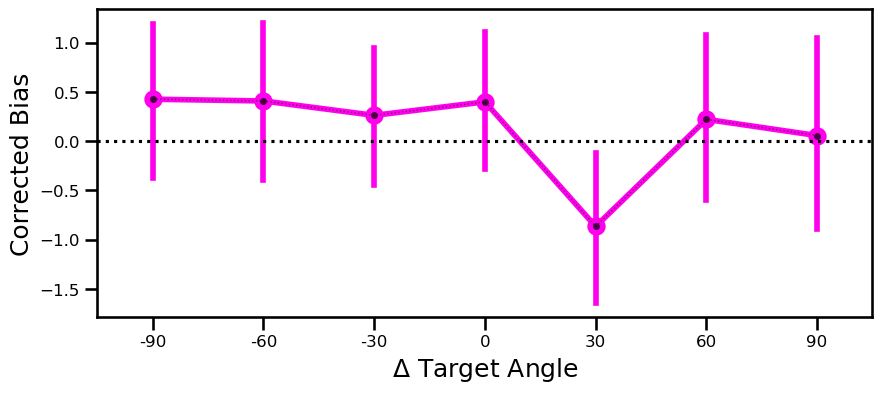

In [20]:
repulse_mask_medium = (
    (df['TN'] >= epochs['repulse_clean'][0]) &
    (df['TN'] < epochs['repulse_clean'][1]) &
    (df["target_angle_diff"].abs() <= 90) &
    (np.abs(df['theta_pv']) < 60) &
    (df['mt'].notna()) & 
    (df['rt'].notna())
)

df_repulse_medium = df.loc[repulse_mask_medium].copy()

subject_means_repulse_medium = (
    df_repulse_medium
    .groupby(['SN', 'target_angle_diff'])['corrected_bias_repulse']
    .mean()
    .reset_index()
)

fig2, ax2 = plt.subplots(figsize=(10,4))

# Group mean + 95% CI
sns.pointplot(
    data=df_repulse_medium,
    x='target_angle_diff',
    y='corrected_bias_repulse',
    estimator='mean',
    errorbar=('ci', 95),
    ax=ax2
)

# Get x-category order for positioning participant lines
x_order = sorted(df_repulse_medium['target_angle_diff'].unique())

# Connect each participant's dots
for sn, sub in subject_means_repulse_medium.groupby('SN'):
    sub = sub.sort_values('target_angle_diff')

    x_positions = [
        x_order.index(x)
        for x in sub['target_angle_diff']
    ]

    ax2.plot(
        x_positions,
        sub['corrected_bias_repulse'],
        color='black',
        linewidth=1,
        linestyle=':',
        alpha=0.5
    )

# Individual participant means
sns.stripplot(
    data=subject_means_repulse_medium,
    x='target_angle_diff',
    y='corrected_bias_repulse',
    color='black',
    alpha=0.7,
    jitter=0,
    size=5,
    ax=ax2
)

ax2.axhline(0, color='black', linestyle=':')
ax2.tick_params(axis='x', labelsize=12)
ax2.tick_params(axis='y', labelsize=12)

plt.xlabel(r'$\Delta$ Target Angle')
plt.ylabel('Corrected Bias')

plt.show()

## REPULSE: only good reach (STRICT)

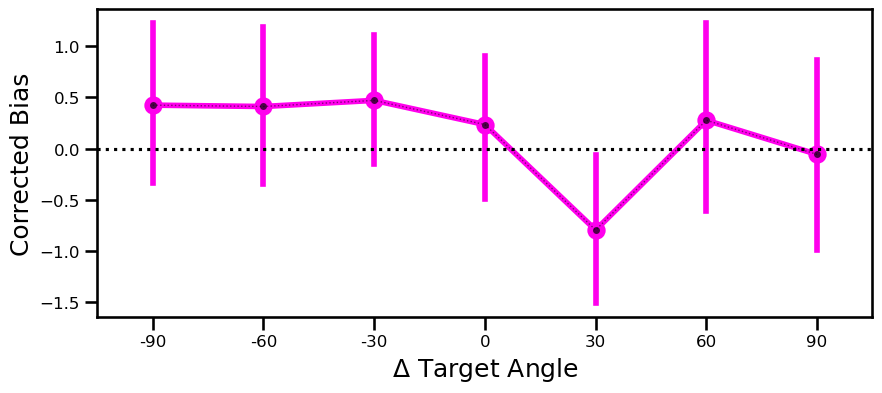

In [21]:
repulse_mask_strict = (
    (df['TN'] >= epochs['repulse_clean'][0]) &
    (df['TN'] < epochs['repulse_clean'][1]) &
    (df["target_angle_diff"].abs() <= 90) &
    (np.abs(df['theta_pv']) < 60) &
    (df['reach_feedback'] == 'good reach')
)

df_repulse_strict = df.loc[repulse_mask_strict].copy()

subject_means_repulse_strict = (
    df_repulse_strict
    .groupby(['SN', 'target_angle_diff'])['corrected_bias_repulse']
    .mean()
    .reset_index()
)

fig2, ax2 = plt.subplots(figsize=(10,4))

# Group mean + 95% CI
sns.pointplot(
    data=df_repulse_strict,
    x='target_angle_diff',
    y='corrected_bias_repulse',
    estimator='mean',
    errorbar=('ci', 95),
    ax=ax2
)

# Get x-category order for positioning the participant lines
x_order = sorted(df_repulse_strict['target_angle_diff'].unique())

# Connect each participant's dots
for sn, sub in subject_means_repulse_strict.groupby('SN'):
    sub = sub.sort_values('target_angle_diff')

    x_positions = [
        x_order.index(x)
        for x in sub['target_angle_diff']
    ]

    ax2.plot(
        x_positions,
        sub['corrected_bias_repulse'],
        color='black',
        linewidth=1,
        linestyle=':',
        alpha=0.5
    )

# Individual participant means
sns.stripplot(
    data=subject_means_repulse_strict,
    x='target_angle_diff',
    y='corrected_bias_repulse',
    color='black',
    alpha=0.7,
    jitter=0,
    size=5,
    ax=ax2
)

ax2.axhline(0, color='black', linestyle=':')
ax2.tick_params(axis='x', labelsize=12)
ax2.tick_params(axis='y', labelsize=12)

plt.xlabel(r'$\Delta$ Target Angle')
plt.ylabel('Corrected Bias')

plt.show()